# **Langgraph**

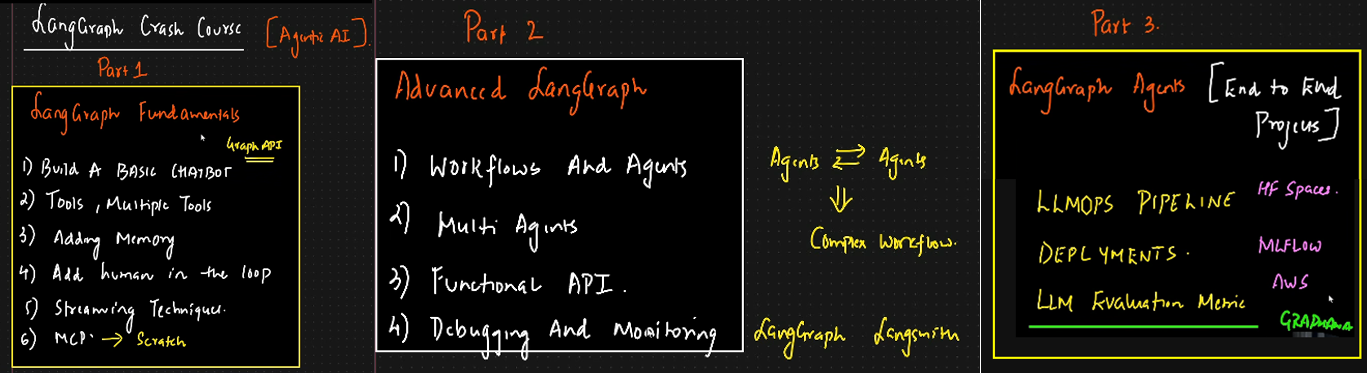

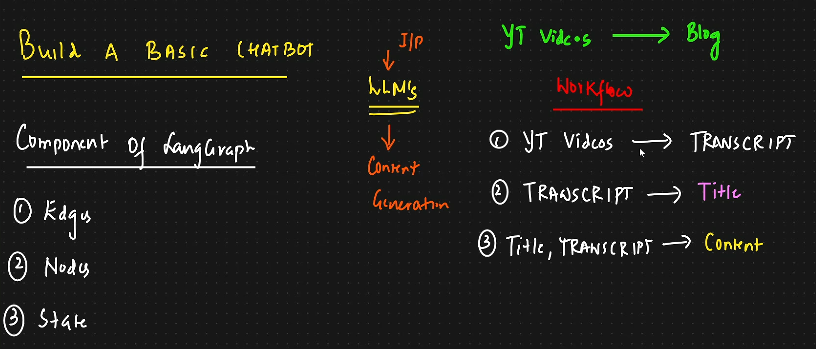

### In Langgraph, to solve this kind of workflow, Graph is required:

1. Graph API (easy and best)
2. Functional API

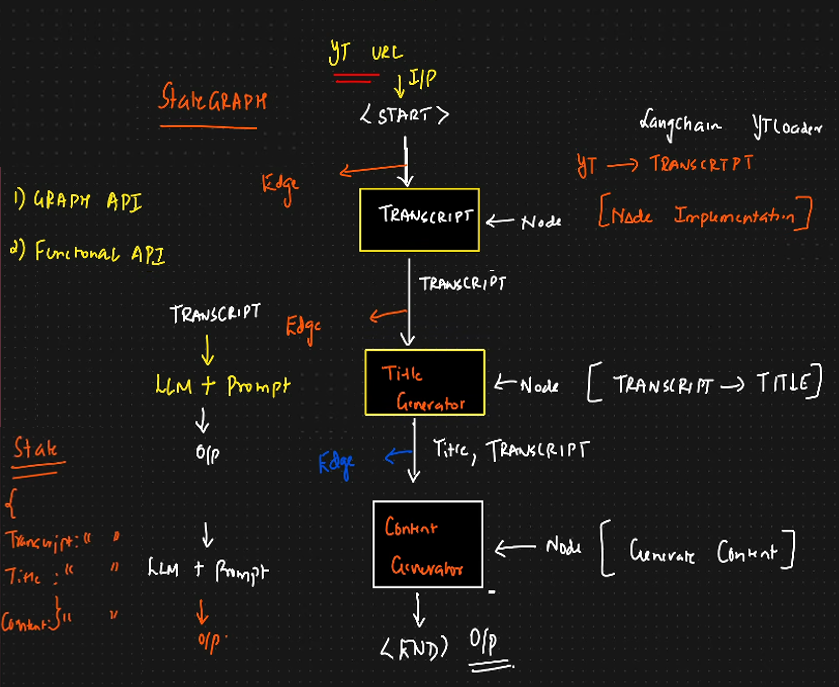

## Build A Basic Chatbot With Langgraph (GRAPH API)

In [1]:
import importlib.metadata

try:
    version = importlib.metadata.version("langgraph")
    print(f"LangGraph version: {version}")
except importlib.metadata.PackageNotFoundError:
    print("LangGraph is not installed.")

LangGraph version: 1.2.20


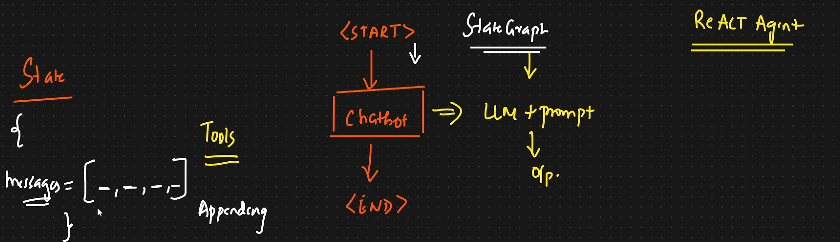

In [2]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

# add_messages is a Reducer function that takes a StateGraph and a list of messages as input, and returns the updated StateGraph with the messages added. 
# It is used to add messages to a StateGraph in a functional programming style.

In [3]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]

graph_builder = StateGraph(State)

In [4]:
graph_builder

In [5]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [6]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm = ChatGroq(model="openai/gpt-oss-20b", temperature=0)
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.7', 'langchain': '1.4.10'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000017E69A602C0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000017E6C5D4110>, model_name='openai/gpt-oss-20b', temperature=1e-08, model_kwargs={}, groq_api_key=SecretStr('**********'))

In [7]:
llm=init_chat_model("groq:openai/gpt-oss-20b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.7', 'langchain': '1.4.10'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000017E6C5D46E0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000017E6C5D4BF0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [8]:
## Node Functionality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

# The return type of the function is a dictionary with a key "messages" that maps to a list of messages. 
# The value of this key is the output of the llm.invoke() method, which takes the current state's messages as input and generates a response.

In [9]:
graph_builder=StateGraph(State)

# Adding node
graph_builder.add_node("llmchatbot",chatbot)
## Adding Edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

# compile the graph
graph=graph_builder.compile()

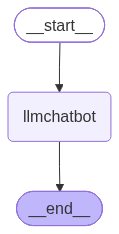

In [10]:
graph

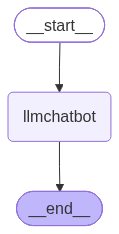

In [11]:
# Visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [12]:
response = graph.invoke({"messages":"Hi"})

In [13]:
response["messages"]

[HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='161dd87c-8093-43eb-98cb-70b43cd6cbaa'),
 AIMessage(content='Hello! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'We need to respond. The user just says "Hi". We should greet back. The user didn\'t ask a question. So we can respond with a friendly greeting and ask how we can help.'}, response_metadata={'token_usage': {'completion_tokens': 60, 'prompt_tokens': 72, 'total_tokens': 132, 'completion_time': 0.063827013, 'completion_tokens_details': {'reasoning_tokens': 40}, 'prompt_time': 0.003952226, 'prompt_tokens_details': None, 'queue_time': 0.476049182, 'total_time': 0.067779239}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_5979a0e1b7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1ca42-dc48-7729-97eb-5a1cbf275e25-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tok

In [14]:
response["messages"][-1].content

'Hello! 👋 How can I help you today?'

In [15]:
for event in graph.stream({"messages":"Hi How are you?"}):
    print(event)

{'llmchatbot': {'messages': [AIMessage(content='Hello! I’m doing great—thanks for asking. How can I help you today?', additional_kwargs={'reasoning_content': 'User greeting: "Hi How are you?" We respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 41, 'prompt_tokens': 76, 'total_tokens': 117, 'completion_time': 0.062677114, 'completion_tokens_details': {'reasoning_tokens': 14}, 'prompt_time': 0.004473261, 'prompt_tokens_details': None, 'queue_time': 0.57878871, 'total_time': 0.067150375}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_816fc87d18', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1ca42-df2f-7348-a508-37d5e4466060-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 76, 'output_tokens': 41, 'total_tokens': 117, 'output_token_details': {'reasoning': 14}})]}}


In [16]:
for event in graph.stream({"messages":"Hi How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hi there! I’m doing great—thanks for asking. How can I help you today?


## Chatbot With Tool

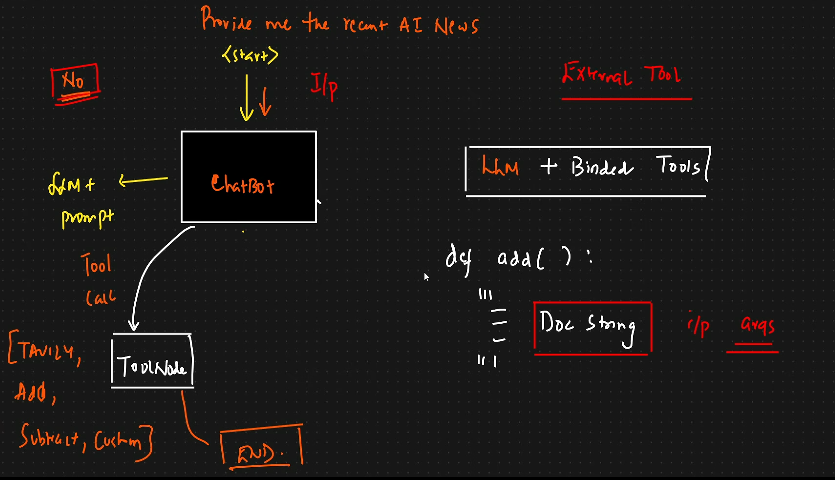

LLM will decide whether it is able to respond or not, if NOT then it will check if it has some TOOL NODEs (Tool information). If the tools exists then the LLM will decide if it has a right tool that will be able to provide relevant responses based on the DocString. Then, the tool will be called.

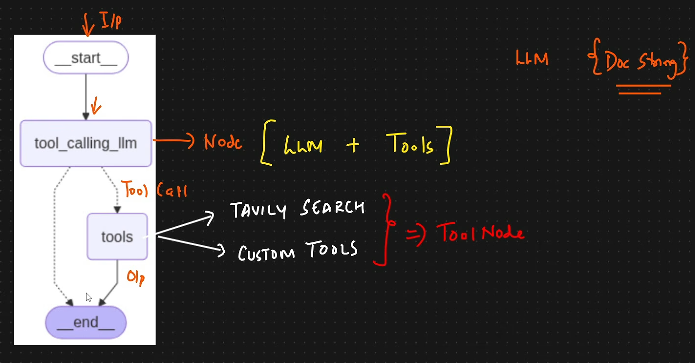

### TavilySearch

It is a real-time, AI-focused search engine and API designed to provide accurate, structured, and up-to-date information for AI agents and large language models (LLMs).

- TavilySearch is a specialized search tool built for AI applications, enabling models to access live web data efficiently. 
- Unlike traditional search engines that primarily return links, Tavily delivers concise, structured summaries of relevant content, making it easier for AI systems to process and reason over factual information without hallucinations. 
- It is particularly useful for retrieval-augmented generation (RAG) workflows, where AI models combine retrieved data with generative responses.

In [17]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("What is langgraph and who has developed it?")

{'query': 'What is langgraph and who has developed it?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.ibm.com/think/topics/langgraph',
   'title': 'What is LangGraph? | IBM',
   'content': 'LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tools and libraries that enable users to create, run and optimize large language models (LLMs) in a scalable and efficient manner. At its core, LangGraph uses the power of graph-based architectures to model and manage the intricate relationships between various components of an AI agent workflow. [...] LangGraph illuminates the processes within an AI workflow, allowing full transparency of the agent’s state. Within LangGraph, the “state” feature serves as a memory bank that records and tracks all the valuable information processed by the AI system. It’s similar to a digital notebook wh

In [21]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("What are the websites that have faced cyber attacks today?")

{'query': 'What are the websites that have faced cyber attacks today?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.csis.org/programs/strategic-technologies-program/significant-cyber-incidents',
   'title': 'Significant Cyber Incidents | Strategic Technologies Program | CSIS',
   'content': 'April 2022.The Romanian National Directorate of Cyber Security said that multiple public and private sector websites were hit with DDoS attacks. The victims included the ministry of defense, border police, national railway company, and the OTP Bank. A group claiming credit for the attack said on Telegram that it hacked the websites because Romania supported Ukraine since the Russian invasion of the country. [...] December 2022.Russia-linked hackers launched a DDoS attack against Vatican City servers, knocking its official website offline. The attack came three days after Russian government officials criticized Pope Francis for his comments about t

In [22]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("Which website has been reported as pshishing today?")

{'query': 'Which website has been reported as pshishing today?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://community.cloudflare.com/t/this-website-has-been-reported-for-potential-phishing/866196',
   'title': 'This website has been reported for potential phishing - Application Security / Bot Management - Cloudflare Community',
   'content': 'When you Log into your Cloudflare dashboard you should see a message providing more details on the reason behind this flagging and how to request a review → \n\nExample:\n\nImage 11: example example 699×306 81 KB\n\n  \n\n Solution \n\n \u200b \n\n \u200b \n\n## Closed on Dec 11, 2025\n\nReply\n\n  \n\nAI bots are scraping your site for free. Take back control — block the ones that don’t send you traffic! \n\nManage AI Crawlers [...] Your security workflow lives in Cloudflare. Your log analysis should too. Log Explorer — SQL-native, zero setup, already connected.\n\nDeploy Log Explorer\n\n.\n> \n> \

In [41]:
# Custom function
def multiply(a:int,b:int)->int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a*b

In [42]:
tools = [tool,multiply]

In [43]:
llm_with_tool = llm.bind_tools(tools)

In [44]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.7', 'langchain': '1.4.10'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000017E6C5D46E0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000017E6C5D4BF0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and

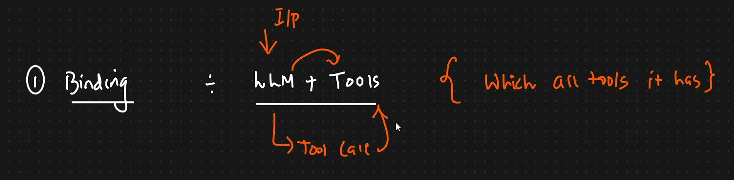

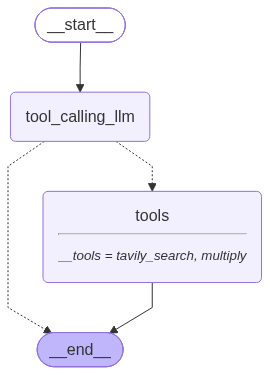

In [54]:
# Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

# Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

# Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

# Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)

builder.add_edge("tools",END)

# compile the graph
graph = builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

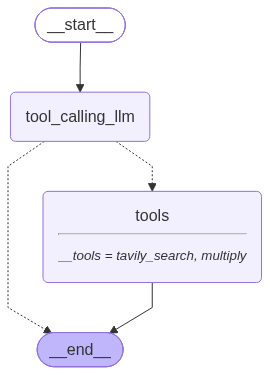

In [55]:
graph

In [56]:
response=graph.invoke({"messages":"What is the recent ai news on 11 Nov 2026?"})

In [57]:
response['messages'][-1].content

'{"query": "AI news November 11 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://yaledailynews.com/articles/yale-clerical-workers-union-to-seek-ai-guardrails-in-upcoming-contract", "title": "Yale clerical workers’ union to seek AI guardrails in upcoming contract | Yale Daily News", "content": "Yale Daily News\\n\\nVOL. CXLIX\\n\\nNew Haven, Connecticut\\n\\nWednesday, November 11, 2026\\n\\nYale Daily News\\n\\n## Newsletters\\n\\nPick the ones you’d open.\\n\\nBy signing up, you agree to receive emails. Unsubscribe at any time.\\n\\n# Yale clerical workers’ union to seek AI guardrails in upcoming contract\\n\\n## A month after Local 34, Yale’s clerical workers’ union, released a report slamming the introduction of artificial intelligence in University workplaces, a union steward said it would prioritize protections against AI in its upcoming contract.\\n\\nStaff Reporter\\n\\nShyam Suva, Contributing Photographer\\n\\nYale’s clerical worke

In [58]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news on 11 Nov 2026?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_45d4dca1-9a50-4127-a2e6-d852d3379dba)
 Call ID: fc_45d4dca1-9a50-4127-a2e6-d852d3379dba
  Args:
    query: AI news November 11 2026
    search_depth: advanced
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "AI news November 11 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://yaledailynews.com/articles/yale-clerical-workers-union-to-seek-ai-guardrails-in-upcoming-contract", "title": "Yale clerical workers’ union to seek AI guardrails in upcoming contract | Yale Daily News", "content": "Yale Daily News\n\nVOL. CXLIX\n\nNew Haven, Connecticut\n\nWednesday, November 11, 2026\n\nYale Daily News\n\n## Newsletters\n\nPick the ones you

In [63]:
response=graph.invoke({"messages":"What is 25 multiplied by 21"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 25 multiplied by 21
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_a3fdbc12-0439-4ec2-8ca3-c5edf5a938e9)
 Call ID: fc_a3fdbc12-0439-4ec2-8ca3-c5edf5a938e9
  Args:
    a: 25
    b: 21
================================= Tool Message =================================
Name: multiply

525


In [67]:
response=graph.invoke({"messages":"What is 50 multiplied by 17 and then multiply 81 by 35"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 50 multiplied by 17 and then multiply 81 by 35
================================== Ai Message ==================================

- 50 × 17 = **850**  
- 81 × 35 = **2 835**


In [64]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 81 by 35"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 81 by 35
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_5072e8c5-e21a-4bda-993a-e219bdefe8b2)
 Call ID: fc_5072e8c5-e21a-4bda-993a-e219bdefe8b2
  Args:
    query: recent AI news
    search_depth: advanced
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/ai/google-ai-updates-july-2026", "title": "The latest AI news we announced in July 2026", "content": "Image 3: The big picture\n\nJuly brought a wave of AI advances to support developers, simplify everyday life, and protect local communities. We gave developers faster, more efficient Gemini models for scaling production agent

The LLM called Tavely tool and exit after giving the output of Recent AI News without providing the output to the other part of input becasue there was no loop to go to LLM.

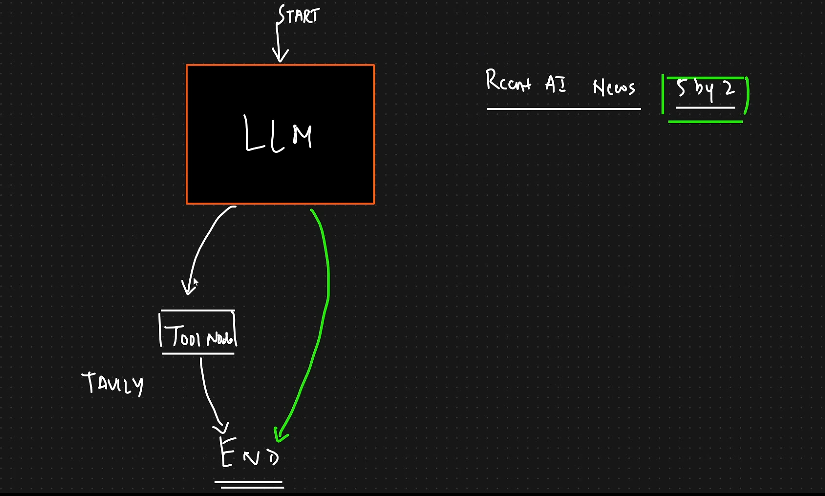

If we make minor changes to graph, LLM will be the main Decision maker and respond to the next queries.

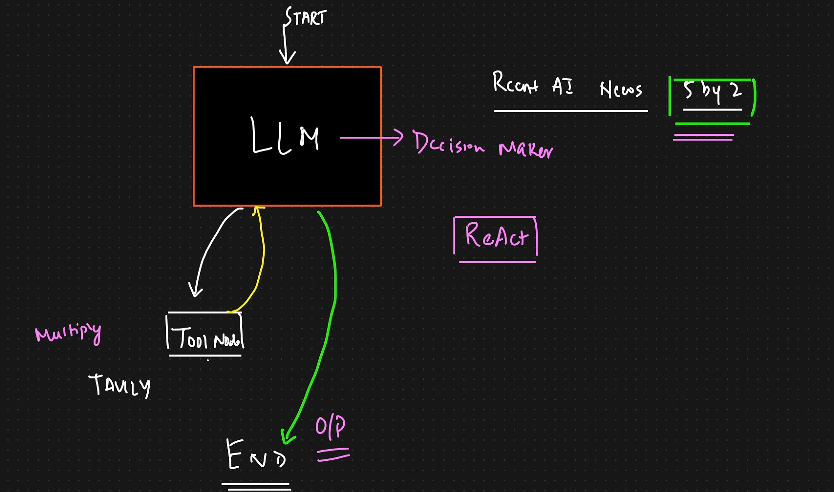

## ReAct Agent Architecture

A ReAct agent is an AI agent that interleaves reasoning (“Thought”) and tool use (“Action”) in a loop, enabling an LLM to think step‑by‑step, call external tools, observe results, and adapt its plan dynamically. It was introduced in the 2022-2023 ReAct paper by Yao et al. and is widely used in modern agent frameworks like LangChain and LangGraph.

What a ReAct Agent Is?
A ReAct agent follows a structured cycle:

- Action: the agent executes a tool call (search, API, calculator, database, etc.).
- Observation: the agent receives the tool’s output and updates its reasoning.
- Reason: the LLM reasons about what to do next.

This loop repeats until the agent determines it has enough information to produce a final answer.

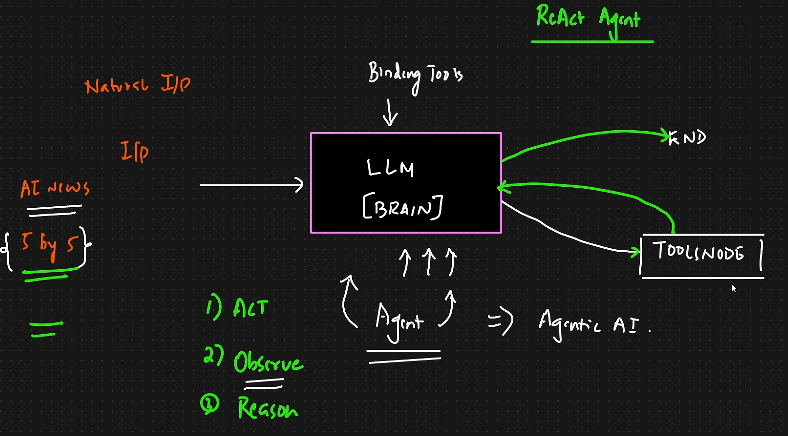

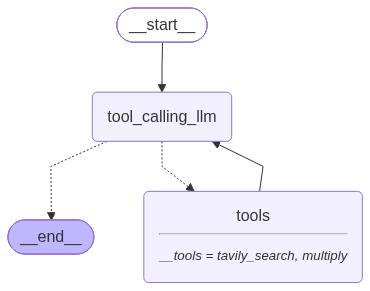

In [68]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [72]:
response=graph.invoke({"messages":"Give me the recent ai news (11 Nov 2026) and then multiply 165 by 81"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news (11 Nov 2026) and then multiply 165 by 81
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_2a45793b-bf20-4a10-940c-31bfe01a06ed)
 Call ID: fc_2a45793b-bf20-4a10-940c-31bfe01a06ed
  Args:
    query: AI news November 11 2026
    search_depth: advanced
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "AI news November 11 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.news4jax.com/business/2026/11/11/asian-shares-mostly-rise-on-ai-chip-demand-despite-wall-streets-retreat-on-inflation-data", "title": "Asian markets mostly gain on AI chip demand despite Wall Street's retreat on inflation data", "content": "Cloudy icon\n\n68º\n\nWJXT logoGo to the WJXT homepage\n\nJoin Insider\n\n#### Business\

```**We can add several tool, LLMs will be the deciding factor, which tool to call.**

#### **We can add several tool, LLMs will be the deciding factor, which tool to call.**

## Adding Memory In Agentic Graph

Persistent Checkpointing

In [75]:
response=graph.invoke({"messages":"Hello my name is Saksham."})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hello my name is Saksham.
================================== Ai Message ==================================

Hello Saksham! How can I help you today?


In [78]:
response=graph.invoke({"messages":"What is my name?"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is my name?
================================== Ai Message ==================================

I’m sorry, but I don’t have that information. Could you let me know your name?


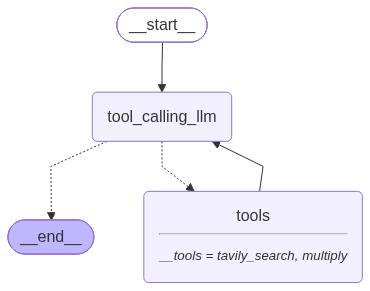

In [ ]:
# Using the same graph
# Using MemorySaver to save the state of the graph and retrieve it later

# Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

# Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

# Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

# Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

# compile the graph with memory checkpointing enabled, allowing the graph to save and retrieve its state across invocations
graph=builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [85]:
# This configuration key should be unique for each user/session to ensure that the state of the graph is saved and retrieved correctly for that specific user/session.

config={"configurable":{"thread_id":"81"}}

response=graph.invoke({"messages":"Hi, my name is Saksham."}, config=config)

response

{'messages': [HumanMessage(content='Hi, my name is Saksham.', additional_kwargs={}, response_metadata={}, id='8aba7fb1-0ed0-49f6-a938-8786fd91ace8'),
  AIMessage(content='Hello Saksham! How can I help you today?', additional_kwargs={'reasoning_content': 'User says "Hi, my name is Saksham." Probably want to respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 40, 'prompt_tokens': 351, 'total_tokens': 391, 'completion_time': 0.041880532, 'completion_tokens_details': {'reasoning_tokens': 19}, 'prompt_time': 0.060647386, 'prompt_tokens_details': None, 'queue_time': 0.126224697, 'total_time': 0.102527918}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_80501ff3a1', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1cab2-d0d8-76b5-ab92-da93e0400c06-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 351, 'output_tokens': 40, 'total_tokens': 391, 'output_token_details':

In [86]:
response['messages'][-1].content

'Hello Saksham! How can I help you today?'

In [87]:
response=graph.invoke({"messages":"Hey what is my name"},config=config)

print(response['messages'][-1].content)

Your name is Saksham.


In [ ]:
response=graph.invoke({"messages":"Hey do you remember my name"},config=config)

print(response['messages'][-1].content)

Absolutely—I remember you’re Saksham.


## Streaming

In [91]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

In [92]:
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

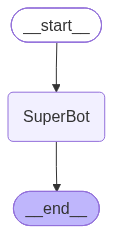

In [93]:
graph=StateGraph(State)

## node
graph.add_node("SuperBot",superbot)
## Edges

graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)


graph_builder=graph.compile(checkpointer=memory)


## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

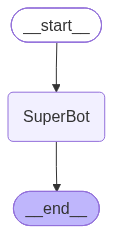

In [95]:
graph_builder

In [96]:
## Invocation

config = {"configurable": {"thread_id": "1"}}

graph_builder.invoke({'messages':"Hi, my name is Saksham and I do not like cricket."},config)

{'messages': [HumanMessage(content='Hi, my name is Saksham and I do not like cricket.', additional_kwargs={}, response_metadata={}, id='f62535ac-4062-4fc5-9786-18c04e309fe0'),
  AIMessage(content='Hello Saksham! 👋 It’s great to meet you. Not a cricket fan—no worries, there are plenty of other sports (and hobbies) out there to explore. What are you into? Whether it’s basketball, soccer, coding, music, or something completely different, I’d love to hear more about your interests and maybe share a few fun facts or recommendations. Feel free to let me know!', additional_kwargs={'reasoning_content': 'We need to respond to user. The user says "Hi, my name is Saksham and I do not like cricket." They didn\'t ask a question but likely want some response. We can acknowledge, ask about interests, maybe suggest other sports. We should be friendly.'}, response_metadata={'token_usage': {'completion_tokens': 149, 'prompt_tokens': 86, 'total_tokens': 235, 'completion_time': 0.16699396, 'completion_tok

**Streaming Methods**: stream() and astream()

- These methods are sync and async methods for streaming back results.

Additional parameters in streaming modes for graph state

- values : This streams the full state of the graph after each node is called.
- updates : This streams updates to the state of the graph after each node is called.

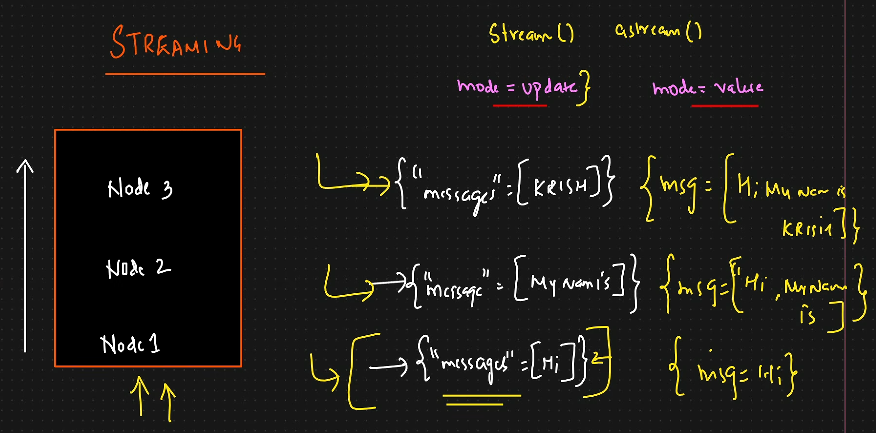

####  Stream

In [97]:
# Create a thread
config = {"configurable": {"thread_id": "3"}}


In [ ]:
for chunk in graph_builder.stream({'messages':"Hi,My name is Saksham and I don't like cricket"},config,stream_mode="updates"):
    print(chunk)

# Here, stream_mode="updates" allows only the last message to be sent to the model, rather than the entire conversation history. This can be useful for reducing the amount of context that the model needs to process, which can improve performance and reduce costs.
# Therefore the output only has AIMessage and not the human message, as the human message is not needed for the model to generate a response.

{'SuperBot': {'messages': [AIMessage(content='Hey Saksham! 👋 Thanks for dropping by. Cricket’s not your thing—no worries at all! What are you into instead? Sports, movies, gaming, coding, or maybe something totally different? I’d love to hear what sparks your interest!', additional_kwargs={'reasoning_content': 'User: "Hi,My name is Saksham and I don\'t like cricket". They just introduced themselves, expressed dislike of cricket. We should respond politely. Maybe ask about their interests? We can respond friendly. No policy conflict. Just normal.'}, response_metadata={'token_usage': {'completion_tokens': 113, 'prompt_tokens': 84, 'total_tokens': 197, 'completion_time': 0.123016815, 'completion_tokens_details': {'reasoning_tokens': 51}, 'prompt_time': 0.00541799, 'prompt_tokens_details': None, 'queue_time': 0.289072551, 'total_time': 0.128434805}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_9340e7d14d', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': N

In [ ]:
for chunk in graph_builder.stream({'messages':"Hi,My name is Saksham and I don't like cricket"},config,stream_mode="values"):
    print(chunk)

# Here, stream_mode="values" allows all the messages to be sent to the model. This can be useful for providing the model with more context, which can improve the quality of the response. 
# However, it may also increase the amount of context that the model needs to process, which can impact performance and costs.
# Therefore the output has AIMessage and HumanMessage.

{'messages': [HumanMessage(content="Hi,My name is Saksham and I don't like cricket", additional_kwargs={}, response_metadata={}, id='97ab096e-e0c5-46a3-99d8-ed1d2d898adc'), AIMessage(content='Hey Saksham! 👋 Thanks for dropping by. Cricket’s not your thing—no worries at all! What are you into instead? Sports, movies, gaming, coding, or maybe something totally different? I’d love to hear what sparks your interest!', additional_kwargs={'reasoning_content': 'User: "Hi,My name is Saksham and I don\'t like cricket". They just introduced themselves, expressed dislike of cricket. We should respond politely. Maybe ask about their interests? We can respond friendly. No policy conflict. Just normal.'}, response_metadata={'token_usage': {'completion_tokens': 113, 'prompt_tokens': 84, 'total_tokens': 197, 'completion_time': 0.123016815, 'completion_tokens_details': {'reasoning_tokens': 51}, 'prompt_time': 0.00541799, 'prompt_tokens_details': None, 'queue_time': 0.289072551, 'total_time': 0.12843480

In [113]:
# Create a thread
config = {"configurable": {"thread_id": "4"}}


In [ ]:
for chunk in graph_builder.stream({'messages':"Hi, my name is Saksham and I don't like football."},config,stream_mode="updates"):
    print(chunk)

# HumnMessage is not retuned as stream_mode="updates" allows only the last message to be sent to the model, rather than the entire conversation history. This can be useful for reducing the amount of context that the model needs to process, which can improve performance and reduce costs.

{'SuperBot': {'messages': [AIMessage(content='Hey Saksham! 👋 I totally get it—football isn’t everyone’s favorite. What *does* get you pumped? Whether it’s a different sport, a hobby, a movie, or something else entirely, I’d love to hear what you’re into!', additional_kwargs={'reasoning_content': "User repeats same statement. They say they don't like football. They keep repeating. We need to respond appropriately. Possibly ask what they like. Also keep conversation. There's no policy violation. Just respond."}, response_metadata={'token_usage': {'completion_tokens': 105, 'prompt_tokens': 461, 'total_tokens': 566, 'completion_time': 0.113361716, 'completion_tokens_details': {'reasoning_tokens': 41}, 'prompt_time': 0.042449442, 'prompt_tokens_details': None, 'queue_time': 0.433534043, 'total_time': 0.155811158}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e23fc997ca', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='l

In [ ]:
for chunk in graph_builder.stream({'messages':"I like hockey."},config,stream_mode="values"):
    print(chunk)

# Previous memory is retained, so the model can remember that the user does not like football and that they like hockey.

{'messages': [HumanMessage(content="Hi,My name is Saksham and I don't like football.", additional_kwargs={}, response_metadata={}, id='8e31bb15-ed42-43ea-b7e7-849a6f180bbd'), AIMessage(content='Hi Saksham! It’s great to meet you. If football isn’t your thing, what’s a sport or activity you do enjoy? Or maybe you’re into something completely different—music, books, gaming? I’d love to hear what you’re passionate about!', additional_kwargs={'reasoning_content': 'The user says: "Hi, My name is Saksham and I don\'t like football." The user might just be stating something. As an assistant, I can respond politely, acknowledge, maybe ask about other sports or interests. There\'s no instruction that forbids me from talking about football. The user says they don\'t like football. I should respond accordingly. The user didn\'t ask a question. So I can respond with a friendly greeting and maybe ask about their interests. I should keep it concise, friendly.'}, response_metadata={'token_usage': {'c

In [116]:
# Create a thread
config = {"configurable": {"thread_id": "5"}}

####  Astream

In [ ]:
async for event in graph_builder.astream_events({"messages":["Hi My name is Saksham and I like to play cricket"]},config,version="v2"):
    print(event)

# The output is an event stream that contains the messages exchanged between the user and the model. 
# Each event in the stream represents a message, and the messages are returned in the order they were sent. 
# The event stream allows for real-time communication with the model, enabling the user to receive responses as they are generated.

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Saksham and I like to play cricket']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a1cacd-6e5d-73b1-bec8-78128ee9e37f', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content="Hi,My name is Saksham and I don't like football.", additional_kwargs={}, response_metadata={}, id='cbd9fc89-de04-49c7-9577-4bd3fb62ca35'), AIMessage(content='Hey Saksham! 👋 That’s totally fine—football isn’t for everyone. What are you into instead? Sports, games, music, books, or something else? I’m all ears!', additional_kwargs={'reasoning_content': 'We need to respond to user. The user says "Hi, My name is Saksham and I don\'t like football." We can respond politely. The user might want to talk about something else? We can ask them what they like, or respond that it\'s okay. There\'s no policy violation. Just respond in a friendl

# Human In the Loop / Feedback

In [ ]:
import os
from langchain.chat_models import init_chat_model
llm = init_chat_model(model="groq:openai/gpt-oss-20b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.7', 'langchain': '1.4.10'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000017E70501250>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000017E7051F890>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [138]:
from typing import Annotated

from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from typing_extensions import TypedDict

from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

from langgraph.types import Command, interrupt

class State(TypedDict):
    messages: Annotated[list, add_messages]

graph_builder = StateGraph(State)

@tool
def human_assistance(query: str) -> str:
    """Request assistance from a human."""
    human_response = interrupt({"query": query})
    return human_response["data"]

tool = TavilySearch(max_results=2)
tools = [tool, human_assistance]
llm_with_tools = llm.bind_tools(tools)

def chatbot(state: State):
    message = llm_with_tools.invoke(state["messages"])
    # Because we will be interrupting during tool execution,
    # we disable parallel tool calling to avoid repeating any
    # tool invocations when we resume.
    
    return {"messages": [message]}

graph_builder.add_node("chatbot", chatbot)

tool_node = ToolNode(tools=tools)
graph_builder.add_node("tools", tool_node)

graph_builder.add_conditional_edges(
    "chatbot",
    tools_condition,
)
graph_builder.add_edge("tools", "chatbot")
graph_builder.add_edge(START, "chatbot")

In [139]:
memory = MemorySaver()

graph = graph_builder.compile(checkpointer=memory)

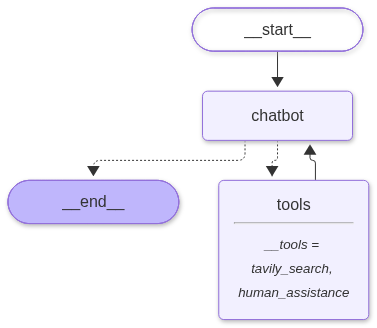

In [140]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    # This requires some extra dependencies and is optional


    pass

In [141]:
# Tool call made to request human assistance instead of using the TavilySearch tool.

user_input = "I need some expert guidance and assistance for building an AI agent. Could you request assistance for me?"
config = {"configurable": {"thread_id": "1"}}

events = graph.stream(
    {"messages": user_input},
    config,
    stream_mode="values",
)

for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

I need some expert guidance and assistance for building an AI agent. Could you request assistance for me?
================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_8a3b1f6e-eeb2-425f-a701-daf0e48dff9e)
 Call ID: fc_8a3b1f6e-eeb2-425f-a701-daf0e48dff9e
  Args:
    query: I need some expert guidance and assistance for building an AI agent.
================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_8a3b1f6e-eeb2-425f-a701-daf0e48dff9e)
 Call ID: fc_8a3b1f6e-eeb2-425f-a701-daf0e48dff9e
  Args:
    query: I need some expert guidance and assistance for building an AI agent.


In [142]:
human_response = (
    "We, the experts are here to help! We'd recommend you check out LangGraph to build your agent."
    " It's much more reliable and extensible than simple autonomous agents."
)

human_command = Command(resume={"data": human_response})

events = graph.stream(human_command, config, stream_mode="values")
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_8a3b1f6e-eeb2-425f-a701-daf0e48dff9e)
 Call ID: fc_8a3b1f6e-eeb2-425f-a701-daf0e48dff9e
  Args:
    query: I need some expert guidance and assistance for building an AI agent.
================================= Tool Message =================================
Name: human_assistance

We, the experts are here to help! We'd recommend you check out LangGraph to build your agent. It's much more reliable and extensible than simple autonomous agents.
================================== Ai Message ==================================

Absolutely—let’s get you started on building a robust AI agent! Below is a practical roadmap, plus some tools and best‑practice tips that can help you from conception to deployment. Feel free to let me know which parts you’d like to dive deeper into or any specific constraints you’re working with (e.g., language, data privacy, real‑time requirements).

--

# Building MCP Server [MCP Integration]

The **MCP Server** is a Model Context Protocol server that lets AI agents (like GitHub Copilot) access external tools, documentation, or cloud resources through a structured, stateful interface. It is used in products such as the Azure MCP Server and the Microsoft Learn MCP Server to enable natural‑language operations over Azure services or Microsoft Learn content.

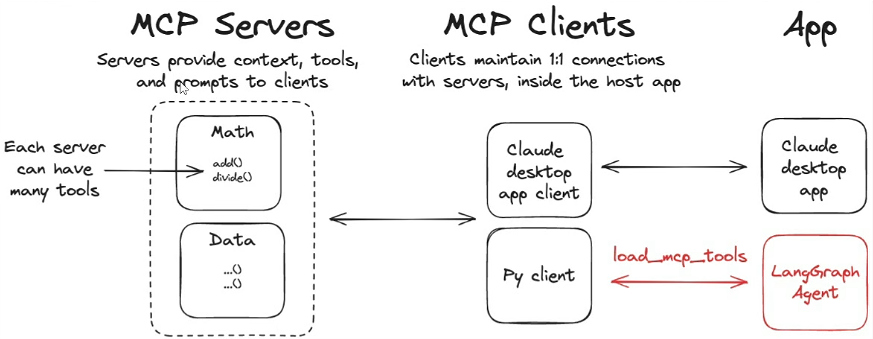

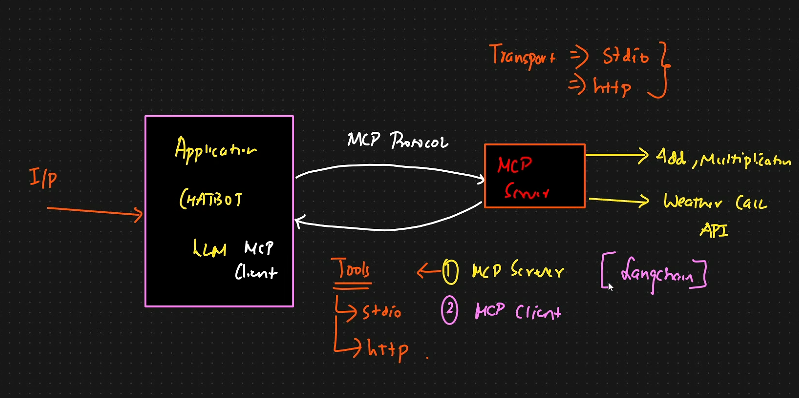